**과제 (강의자료 Ch1-2 p61, Homework 1)**
- Exercise 2.5를 푼다.
- Sample-average, Constant, (General) Weighted-average step-size 알고리즘을 비교한다.
- 가장 좋은 step-size 알고리즘을 고르고, 최적 ε 값을 찾는다.

In [3]:
import os, time
import numpy as np
import matplotlib.pyplot as plt

K = 10              # 10-armed
STEPS = 10_000      # 한 run의 스텝 수 (from Exercise 2.5)
RUNS = 2000         # 반복 실험 수 (from Figure 2.2)
EPSILON = 0.1       # Exercise 2.5가 지정한 ε 값
ALPHA = 0.1         # Constant step-size
WALK_STD = 0.01     # q*(a)의 random walk 표준편차

os.makedirs('figures', exist_ok=True)  # 결과물 저장용

**실험 환경**

**Nonstationary 10-armed testbed (Exercise 2.5)**
- 초기값 q_*(a)=0 
- 매 스텝 모든 행동에 대해 $q_*(a) \leftarrow q_*(a) + \mathcal N(0,\,0.01^2)$ (random walk)
- 보상 $R_t \sim \mathcal N(q_*(A_t),\,1)$

**교재 p.32 simple bandit algorithm**
$$Q(A) \leftarrow Q(A) + \alpha_n \,[R - Q(A)]$$

- Sample-average: $\alpha_n$ :  $1/n$ 
- Constant: $\alpha_n$ : $\alpha=0.1$ 
- (General) Weighted-average step-size: $\alpha_n$ : $1/\sqrt{n}$ 

In [4]:
def run_experiment(method, eps, steps=STEPS, runs=RUNS, alpha=ALPHA,
                   walk_std=WALK_STD, seed=0):
    
    rng = np.random.default_rng(seed)
    q_true = np.zeros((runs, K))   
    Q = np.zeros((runs, K))        
    N = np.zeros((runs, K))        # 행동별 선택 횟수 N(a)
    idx = np.arange(runs)

    avg_reward = np.zeros(steps)
    optimal_rate = np.zeros(steps)

    for t in range(steps):
        # ε-greedy 행동 선택: greedy 행동이 여러개일 경우 그중 무작위로 택한 것
        tie_break = rng.random((runs, K))
        is_max = (Q == Q.max(axis=1, keepdims=True))
        greedy = np.argmax(np.where(is_max, tie_break, -1.0), axis=1)
        explore = rng.random(runs) < eps
        A = np.where(explore, rng.integers(0, K, runs), greedy)

        # 보상 
        R = rng.normal(q_true[idx, A], 1.0)

        avg_reward[t] = R.mean() # 평균 보상
        optimal_rate[t] = (A == q_true.argmax(axis=1)).mean() # 최적 행동을 골랐는지 기록 (비정상 환경이라)

        # step-size 결정 (N을 먼저 +1 해야 1/n에서 0으로 나누지 않음)
        N[idx, A] += 1
        n = N[idx, A]
        if method == 'sample':
            step_size = 1.0 / n
        elif method == 'constant':
            step_size = alpha
        elif method == 'weighted':
            step_size = 1.0 / np.sqrt(n)
        else:
            raise ValueError(method)

        # 업데이트: Q <- Q + α(R - Q)
        Q[idx, A] += step_size * (R - Q[idx, A])

        # 환경 변화: 모든 q*(a)가 random walk ; 비정상 환경을 만드는 원인
        q_true += rng.normal(0.0, walk_std, (runs, K))

    return avg_reward, optimal_rate

**1. 가장 좋은 step-size 찾기**

- Sample-average: $\alpha_n$ :  $1/n$ 
- Constant: $\alpha_n$ : $\alpha=0.1$ 
- (General) Weighted-average step-size: $\alpha_n$ : $1/\sqrt{n}$ 

Sample-average (1/n)         done in 6.1s
Constant (alpha=0.1)         done in 5.9s
Weighted (1/sqrt(n))         done in 5.9s


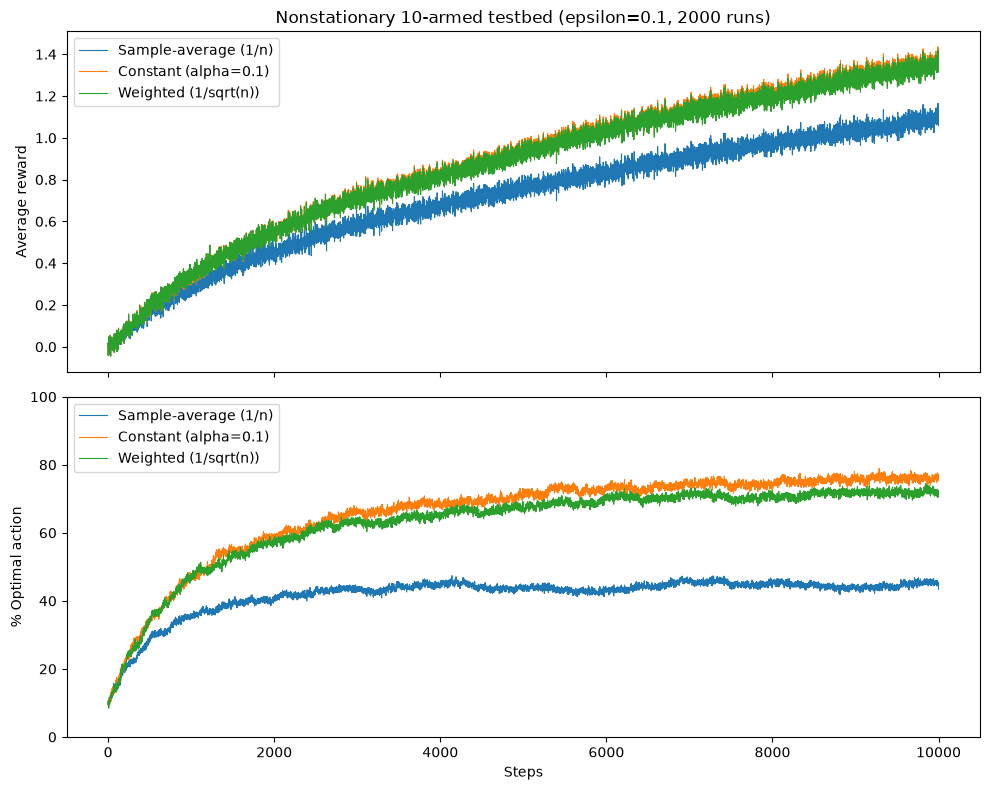

In [5]:
methods = {
    'sample':   'Sample-average (1/n)',
    'constant': f'Constant (alpha={ALPHA})',
    'weighted': 'Weighted (1/sqrt(n))',
}
results = {}
for m in methods:
    t0 = time.time()
    results[m] = run_experiment(m, EPSILON)
    print(f'{methods[m]:28s} done in {time.time()-t0:.1f}s')

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for m, label in methods.items():
    r, o = results[m]
    axes[0].plot(r, label=label, lw=0.8)
    axes[1].plot(o * 100, label=label, lw=0.8)
axes[0].set_ylabel('Average reward')
axes[1].set_ylabel('% Optimal action')
axes[1].set_xlabel('Steps')
axes[0].set_title(f'Nonstationary 10-armed testbed (epsilon={EPSILON}, {RUNS} runs)')
axes[0].legend(); axes[1].legend()
axes[1].set_ylim(0, 100)
plt.tight_layout()
plt.savefig('figures/stepsize_comparison.png', dpi=150)
plt.show()

In [6]:
# 구간별 수치 요약
def summary(arr, a, b):
    return arr[a:b].mean()

print(f"{'Method':28s} | {'reward 0-1k':>11s} | {'reward last 5k':>14s} | {'%opt 0-1k':>9s} | {'%opt last 5k':>12s}")
for m, label in methods.items():
    r, o = results[m]
    print(f"{label:28s} | {summary(r,0,1000):11.3f} | {summary(r,5000,STEPS):14.3f} | "
          f"{summary(o,0,1000)*100:8.1f}% | {summary(o,5000,STEPS)*100:11.1f}%")

Method                       | reward 0-1k | reward last 5k | %opt 0-1k | %opt last 5k
Sample-average (1/n)         |       0.154 |          0.936 |     26.4% |        44.4%
Constant (alpha=0.1)         |       0.179 |          1.170 |     32.1% |        74.3%
Weighted (1/sqrt(n))         |       0.179 |          1.156 |     31.7% |        70.5%


**1-1. 그래프 분석 및 결과**

세 방법 중 Constant가 가장 결과값이 좋았다; 마지막 5,000 스텝에서 최적 행동 선택 비율이 74.3%로 Weighted (70.5%)와 Sample-average(44.4%)보다 높았고, 평균 보상도 1.170으로 가장 높았다. 이 환경은 q*(a)가 매 스텝 random walk로 변하는 비정상 환경인데, 이 경우 최근 보상에 더 큰 가중치를 주는 상수 step-size가 변화를 계속 따라갈 수 있기 때문이다. Constant가 이에 해당한다 : $$Q_{n+1} = (1-\alpha)^n Q_1 + \sum_{i=1}^{n} \alpha(1-\alpha)^{n-i} R_i$$

1/n(Sample-average)은 선택의 횟수가 늘수록 step-size가 0에 가까워져 새 보상을 거의 반영하지 못해서 낮고, 1/√n(Weighted)은 더 천천히 줄어 Constant에 가깝지만 결국 Sample-average와 유사하게 0으로 감소하므로 Constant와 비교하여 미세하게 낮은 성능을 보였다. 

**2. 최적 ε 값을 찾기**

- 세 방법 모두에 대해 ε(8개)을 바꿔가며 마지막 5,000 스텝(학습 초기를 제외하기 위함)의 평균 보상을 비교하자 (교재 Figure 2.6, Exercise 2.11의 parameter study 방식).
- 계산 시간을 줄이기 위해 이 실험은 run 수를 1000으로 한다.
- seed = 1 ; 같은 시드를 쓰면 실험 1과 겹치는 데이터로 확인하는 셈이라 다른 표본에서도 비슷한 결론이 나는지 검증하기 위해 변환.

sweep done in 82.3s


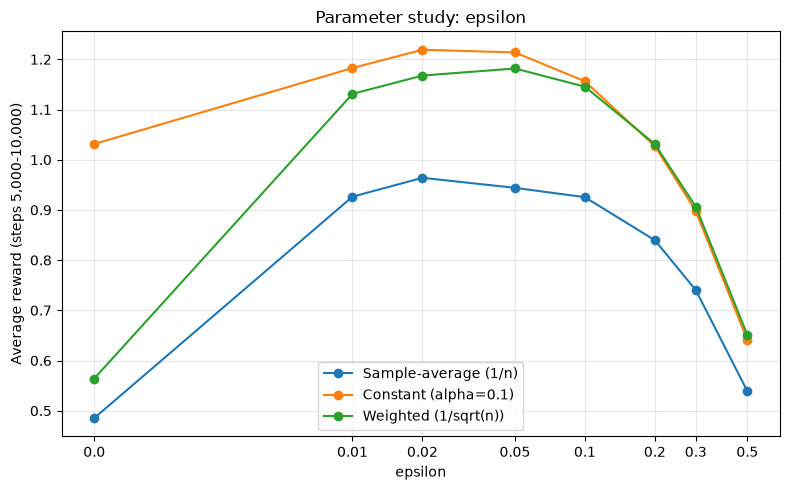

In [7]:
eps_list = [0.0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
SWEEP_RUNS = 1000
sweep = {m: [] for m in methods}

t0 = time.time()
for m in methods:
    for eps in eps_list:
        r, o = run_experiment(m, eps, runs=SWEEP_RUNS, seed=1)
        sweep[m].append(r[5000:].mean())
print(f'sweep done in {time.time()-t0:.1f}s')

plt.figure(figsize=(8, 5))
for m, label in methods.items():
    plt.plot(eps_list, sweep[m], 'o-', label=label)
plt.xscale('symlog', linthresh=0.01)
plt.xticks(eps_list, [str(e) for e in eps_list])
plt.xlabel('epsilon')
plt.ylabel('Average reward (steps 5,000-10,000)')
plt.title('Parameter study: epsilon')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/epsilon_sweep.png', dpi=150)
plt.show()

In [8]:
print(f"{'epsilon':>8s} | " + ' | '.join(f'{methods[m]:>26s}' for m in methods))
for i, eps in enumerate(eps_list):
    print(f'{eps:8.2f} | ' + ' | '.join(f'{sweep[m][i]:26.3f}' for m in methods))

best_method = max(methods, key=lambda m: max(sweep[m]))
best_eps = eps_list[int(np.argmax(sweep[best_method]))]
print(f'\nBest step-size method: {methods[best_method]}')
print(f'Optimal epsilon for it: {best_eps}  (avg reward = {max(sweep[best_method]):.3f})')

 epsilon |       Sample-average (1/n) |       Constant (alpha=0.1) |       Weighted (1/sqrt(n))
    0.00 |                      0.485 |                      1.031 |                      0.564
    0.01 |                      0.926 |                      1.183 |                      1.131
    0.02 |                      0.964 |                      1.219 |                      1.168
    0.05 |                      0.944 |                      1.214 |                      1.182
    0.10 |                      0.925 |                      1.156 |                      1.145
    0.20 |                      0.840 |                      1.027 |                      1.031
    0.30 |                      0.740 |                      0.898 |                      0.906
    0.50 |                      0.539 |                      0.641 |                      0.651

Best step-size method: Constant (alpha=0.1)
Optimal epsilon for it: 0.02  (avg reward = 1.219)


**2-1. 그래프 분석 및 결과**

세가지 방식 중 Constant가 평균 보상이 전체적으로 높았다. 그리고 Constant의 최적의 앱실론은 0.02라는 결과가 나왔다. 0~0.5의 범위 안에서 앱실론의 값이 0.02~0.05 일때 가장 평균 보상이 좋고 그 이후에 다시 낮아지는 현상을 관찰할 수 있다(모든 방식의 공통적인 현상이다). 꼭 앱실론이 높다고 좋은 것이 아니라는 것을 알 수 있었다.